In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("ZURU_Category_Test_2027.csv")
df.head()

,date,product_id,product_name,channel,sales,units,store_selling
0,2024-03-02,3504926,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,instore,13258.29,4751.0,669.0
1,2024-03-02,3504926,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,online,1084.12,388.0,99.0
2,2024-03-02,4643054,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,instore,5567.62,1991.0,542.0
3,2024-03-02,4643054,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,online,383.84,138.0,59.0
4,2024-03-02,6715172,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,instore,14.00,5.0,3.0


Data Exploration

In [3]:
#数据基本信息 Basic info

print("数据行数和列数：")
print(df.shape)
print("\n各列名称：")
print(df.columns.tolist())
print("\n数据类型：")
print(df.dtypes)

数据行数和列数：
(6360, 7)

各列名称：
['date', 'product_id', 'product_name', 'channel', 'sales', 'units', 'store_selling']

数据类型：
date                 str
product_id         int64
product_name         str
channel              str
sales            float64
units            float64
store_selling    float64
dtype: object


In [4]:
print("Missing Values:")
print(df.isnull().sum())
print("Duplicated rows：", df.duplicated().sum())

Missing Values:
date               0
product_id         0
product_name       0
channel            0
sales            261
units            261
store_selling    261
dtype: int64
Duplicated rows： 0


In [5]:
#基本统计数据 Basic Statistics

df[["sales", "units", "store_selling"]].describe()

,sales,units,store_selling
count,6099.000000,6099.000000,6099.000000
mean,10089.760592,2310.955894,377.047057
std,14397.127640,3250.064603,273.435744
min,-7.800000,-2.000000,1.000000
25%,1173.155000,271.000000,125.500000
50%,3564.940000,830.000000,306.000000
75%,14589.085000,3335.000000,643.500000
max,241315.350000,48490.000000,855.000000


Data Aggregation

In [6]:
#转化日期格式 Transform date format
df["date"] = pd.to_datetime(df["date"])

print(df["date"].dtype)

datetime64[us]


In [7]:
channel_summary = df.groupby("channel").agg(
    total_sales = ("sales","sum"),
    total_units = ("units", "sum"),
    record_count = ("sales", "count")
)
display(channel_summary)

#按照月份，汇总销售额、销量
df["month"] = df["date"].dt.to_period("M")
monthly_summary = df.groupby("month").agg(
    total_sales = ("sales", "sum"),
    total_units = ("units", "sum"),
    record_count = ("sales", "count")
).sort_index()
display(monthly_summary.head(5))

,total_sales,total_units,record_count
channel,,,
instore,56524810.77,12961926.0,3180
online,5012639.08,1132594.0,2919


,total_sales,total_units,record_count
month,,,
2024-03,2753931.59,616770.0,310
2024-04,2346819.82,509999.0,244
2024-05,2472477.81,600643.0,233
2024-06,2949934.47,648891.0,288
2024-07,2539946.62,573711.0,231


Time Series Analysis, Growth Rate（根据月份为标准 Monthly）

In [8]:
#环比增长率（MOM）、同比增长率（YOY）
#销售额MOM
monthly_summary["sales_mom"] = (
    monthly_summary["total_sales"].pct_change(fill_method=None)*100
)
#销量MOM
monthly_summary["units_mom"] = (
    monthly_summary["total_units"].pct_change(fill_method=None)*100
)

monthly_summary = monthly_summary.asfreq("M")
#销售额YOY
monthly_summary["sales_yoy"] = (
    monthly_summary["total_sales"].pct_change(periods=12, fill_method=None)*100
)
#销量YOY
monthly_summary["units_yoy"] = (
    monthly_summary["total_units"].pct_change(periods=12, fill_method=None)*100
)
display(monthly_summary.tail(5))

,total_sales,total_units,record_count,sales_mom,units_mom,sales_yoy,units_yoy
month,,,,,,,
2025-08,3248160.39,758083.0,312,10.417534,13.394322,8.122235,10.549142
2025-09,2399161.23,518616.0,272,-26.137846,-31.588494,1.858169,0.581048
2025-10,2788600.26,729161.0,274,16.232299,40.597475,4.359500,17.269180
2025-11,3064361.82,643196.0,343,9.888888,-11.789577,-0.652651,-13.936097
2025-12,2882186.21,667956.0,271,-5.944977,3.849526,2.996436,2.210994


In [9]:
#添加平均单位销售额ASP
monthly_summary["asp"]=(
    monthly_summary["total_sales"]/
    monthly_summary["total_units"]
)

display(monthly_summary)

,total_sales,total_units,record_count,sales_mom,units_mom,sales_yoy,units_yoy,asp
month,,,,,,,,
2024-03,2753931.59,616770.0,310,NaN,NaN,NaN,NaN,4.465087
2024-04,2346819.82,509999.0,244,-14.782930,-17.311315,NaN,NaN,4.601617
2024-05,2472477.81,600643.0,233,5.354394,17.773368,NaN,NaN,4.116385
2024-06,2949934.47,648891.0,288,19.310857,8.032725,NaN,NaN,4.546117
2024-07,2539946.62,573711.0,231,-13.898202,-11.585921,NaN,NaN,4.427223
2024-08,3004155.81,685743.0,286,18.276336,19.527602,NaN,NaN,4.380877
2024-09,2355394.03,515620.0,259,-21.595477,-24.808565,NaN,NaN,4.568081
2024-10,2672109.63,621784.0,272,13.446396,20.589581,NaN,NaN,4.297489
2024-11,3084492.79,747347.0,336,15.432868,20.193990,NaN,NaN,4.127257


Visualization

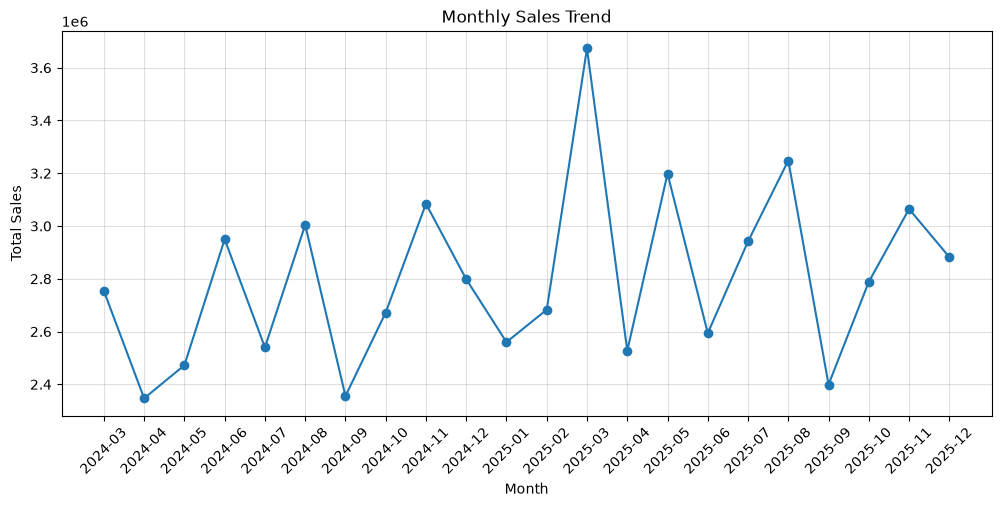

In [10]:
plt.figure(figsize = (12, 5))

plt.plot(
    monthly_summary.index.astype(str),
    monthly_summary["total_sales"],
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.4)
plt.xticks(rotation=45)
plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [11]:
channel_monthly = df.groupby(
    ["month", "channel"]
)["sales"].sum().unstack()

display(channel_monthly.head(6))

channel,instore,online
month,,
2024-03,2572177.38,181754.21
2024-04,2191097.54,155722.28
2024-05,2296462.73,176015.08
2024-06,2738916.55,211017.92
2024-07,2352364.68,187581.94
2024-08,2775796.86,228358.95


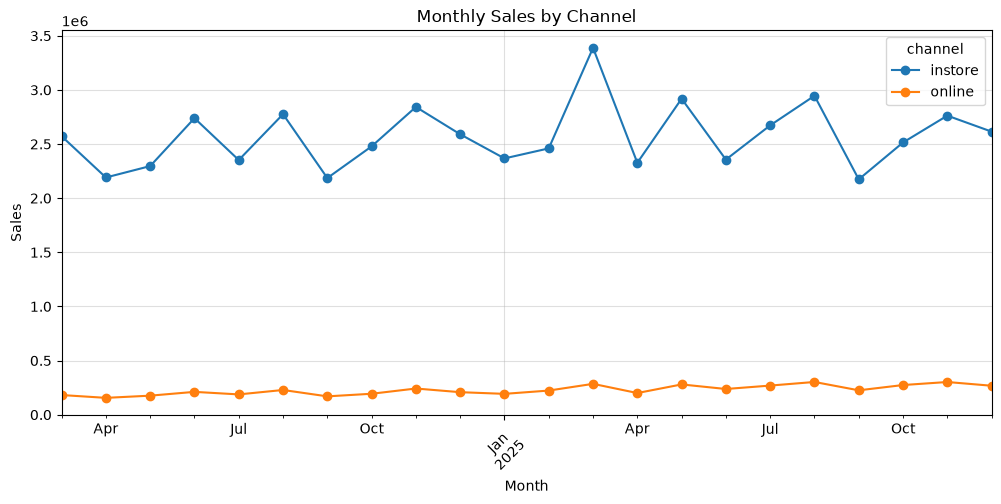

In [12]:
channel_monthly.plot(
    figsize = (12, 5),
    kind = "line",
    marker = "o"
)
plt.title("Monthly Sales by Channel")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.4)
plt.savefig(
    "Monthly_Sales_by_Channel.png",
    dpi = 300,
    bbox_inches = "tight"
)
plt.show()

Channel Sales Share, Volumn Share

In [13]:
#线上、线下销售渠道销售额、销量占比

total_sales = channel_summary["total_sales"].sum()
channel_summary["sales_share"] = (
    channel_summary["total_sales"] / total_sales * 100
).round(4)

total_units = channel_summary["total_units"].sum()
channel_summary["volumn_share"] = (
    channel_summary["total_units"] / total_units * 100
).round(4)

display(channel_summary)

,total_sales,total_units,record_count,sales_share,volumn_share
channel,,,,,
instore,56524810.77,12961926.0,3180,91.8543,91.9643
online,5012639.08,1132594.0,2919,8.1457,8.0357


产品表现分析 Product Performance Analysis

In [14]:
#Group by product ID and name, calculate total sales and total units, descending order

product_summary = df.groupby(
    ["product_id", "product_name"]
).agg(
    total_sales = ("sales", "sum"),
    total_units = ("units", "sum"),
    record_count = ("sales", "count")
).sort_values(
    by = "total_sales",
    ascending = False
)

display(product_summary.head(6))

,,total_sales,total_units,record_count
product_id,product_name,,,
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,5297020.96,665875.0,192
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,4755693.66,588920.0,192
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,3968620.34,484695.0,192
9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 350G:TASTY CHICKEN:.:350 GRAM,3716446.26,259759.0,192
7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BEEF:.:180 GRAM,3393133.48,426454.0,192
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,2732688.04,849299.0,192


In [15]:
#Product sales share
total_product_sales = product_summary["total_sales"].sum()

product_summary["sales_share"] = (
    product_summary["total_sales"] / total_product_sales * 100
).round(4)

display(product_summary.head(6))

,,total_sales,total_units,record_count,sales_share
product_id,product_name,,,,
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,5297020.96,665875.0,192,8.6078
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,4755693.66,588920.0,192,7.7281
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,3968620.34,484695.0,192,6.4491
9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 350G:TASTY CHICKEN:.:350 GRAM,3716446.26,259759.0,192,6.0393
7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BEEF:.:180 GRAM,3393133.48,426454.0,192,5.5139
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,2732688.04,849299.0,192,4.4407


In [16]:
#Product Volumn Share and ASP

total_product_units = product_summary["total_units"].sum()
product_summary["volumn_share"] = (
    product_summary["total_units"] / total_product_units * 100
).round(4)

product_summary["asp"] = (
    product_summary["total_sales"] / 
    product_summary["total_units"].replace(0, float("nan"))
).round(2)

display(product_summary.head(10))

,,total_sales,total_units,record_count,sales_share,volumn_share,asp
product_id,product_name,,,,,,
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,5297020.96,665875.0,192,8.6078,4.7244,7.95
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,4755693.66,588920.0,192,7.7281,4.1784,8.08
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,3968620.34,484695.0,192,6.4491,3.4389,8.19
9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 350G:TASTY CHICKEN:.:350 GRAM,3716446.26,259759.0,192,6.0393,1.8430,14.31
7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BEEF:.:180 GRAM,3393133.48,426454.0,192,5.5139,3.0257,7.96
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,2732688.04,849299.0,192,4.4407,6.0257,3.22
5903522,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FLAVOUR 4X12G SACHETS:TUNA AND SALMON:.:4 PACK,2681787.84,833640.0,192,4.3580,5.9146,3.22
7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G BAG:TURKEY:.:85 GRAM,2571399.65,560921.0,192,4.1786,3.9797,4.58
6722290,DINE CREAMY TREATS CAT TREATS TUNA & PRAWN FLAVOUR 4X12G SACHETS:TUNA & PRAWN:.:4 PACK,2520891.49,787024.0,192,4.0965,5.5839,3.20


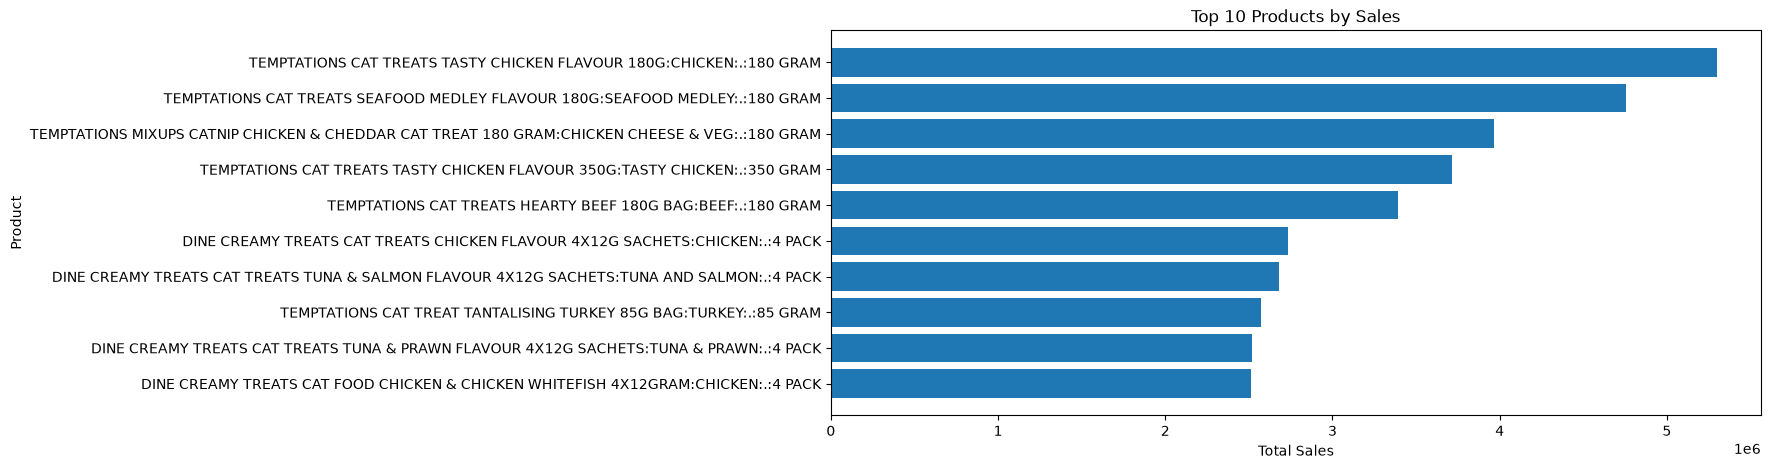

In [17]:
top10_products = product_summary.head(10)

plt.figure(figsize=(12, 5))
plt.barh(
    top10_products.index.get_level_values("product_name"),
    top10_products["total_sales"]
)
plt.gca().invert_yaxis()
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.savefig(
    "Top10_Products_by_Sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Product * Channel Analysis

In [18]:
#产品在不同渠道的表现分析

product_channel = df.groupby(
    ["product_id", "product_name", "channel"]
).agg(
    total_sales = ("sales", "sum"),
    total_units = ("units", "sum")
)
display(product_channel.head(10))

product_channel_sales = product_channel["total_sales"].unstack("channel")
display(product_channel_sales.head(10))

total_sales  \
product_id product_name                                       channel                
2206566    PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12G... instore     43133.79   
                                                              online       2372.56   
2384320    PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 PACK instore    103717.44   
                                                              online       9039.84   
2385946    TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS CA... instore         5.50   
                                                              online          0.00   
2387538    CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM:... instore    106250.87   
                                                              online       6801.38   
2387544    CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 56... instore     94154.59   
                                                              online       5573.37   

                                                                       total_units  
product_id product_name                                       channel               
2206566    PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12G... instore      15483.0  
                                                              online         853.0  
2384320    PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 PACK instore       8686.0  
                                                              online         759.0  
2385946    TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS CA... instore          1.0  
                                                              online           0.0  
2387538    CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM:... instore      30362.0  
                                                              online        2049.0  
2387544    CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 56... instore      27033.0  
                                                              online        1728.0

,channel,instore,online
product_id,product_name,,
2206566,PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12G:4 PACK,43133.79,2372.56
2384320,PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 PACK,103717.44,9039.84
2385946,TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS CATNIP:.:85 GRAM,5.50,0.00
2387538,CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM:CHICKEN:.:56 GRAM,106250.87,6801.38
2387544,CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 56 GRAM:TUNA SALMON:.:56 GRAM,94154.59,5573.37
3504926,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:30 GRAM,1429111.27,132589.76
4643054,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKEREL LOIN:.:30 GRAM,687304.25,57875.27
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,2427824.11,304863.93
5903522,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FLAVOUR 4X12G SACHETS:TUNA AND SALMON:.:4 PACK,2407409.75,274378.09


In [19]:
#Online Sales Share
product_channel_share = product_channel_sales.copy()

product_channel_share["total_sales"] = (
    product_channel_share.sum(axis=1)
)
product_channel_share["online_share"] = (
    product_channel_share["online"] /
    product_channel_share ["total_sales"] * 100
).round(4)
product_channel_share = product_channel_share.sort_values(
    by = "online_share",
    ascending=False
)
display(product_channel_share.head(10))

,channel,instore,online,total_sales,online_share
product_id,product_name,,,,
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,2427824.11,304863.93,2732688.04,11.1562
5903522,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FLAVOUR 4X12G SACHETS:TUNA AND SALMON:.:4 PACK,2407409.75,274378.09,2681787.84,10.2312
7627602,DINE CREAMY TREATS CAT TREATS MIXED SEAFOOD FLAVOUR 4X12G SACHETS:MIXED SEAFOOD VARIETY:.:4 PACK,1141188.88,128252.66,1269441.54,10.1031
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,4766021.90,530999.06,5297020.96,10.0245
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,4305387.07,450306.59,4755693.66,9.4688
8555416,FUSSY CAT GRAIN FREE CRUNCHERS ADULT CAT TREATS CHICKEN 100 GRAM:CHICKEN:.:100 GRAM,1933960.49,199323.21,2133283.70,9.3435
5903570,DINE CREAMY TREATS TUNA FLAVOUR CAT TREATS 4X12G SACHETS:TUNA:.:4 PACK,1553834.74,144882.22,1698716.96,8.5289
3504926,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:30 GRAM,1429111.27,132589.76,1561701.03,8.4901
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,3634791.88,333828.46,3968620.34,8.4117


Product Monthly Sales Trend

In [20]:
product_monthly = df.groupby(
    ["month", "product_id"]
).agg(
    total_sales = ("sales", "sum"),
    total_units = ("units", "sum")
)
display(product_monthly.head(10))

product_sales_trend = (
    product_monthly["total_sales"]
    .unstack("product_id")
)
display(product_sales_trend.head(5))

total_sales  total_units
month   product_id                          
2024-03 3504926        85093.25      32979.0
        4643054        34676.16      13416.0
        5903520       132955.68      37726.0
        5903522       137430.06      38989.0
        5903570        83141.68      23662.0
        6715172          173.62         75.0
        6722290       130400.91      37054.0
        7209098        54704.91      12015.0
        7209122       106459.92      23145.0
        7209148           34.13         14.0

product_id,2206566,2384320,2385946,2387538,2387544,3504926,4643054,5903520,5903522,5903570,...,13685672,13685744,13685854,13685920,15581338,15581366,16957526,16965870,16965892,16965914
month,,,,,,,,,,,,,,,,,,,,,
2024-03,NaN,NaN,NaN,NaN,NaN,85093.25,34676.16,132955.68,137430.06,83141.68,...,60148.10,118495.70,127588.11,101424.84,NaN,NaN,NaN,NaN,NaN,NaN
2024-04,NaN,NaN,NaN,NaN,NaN,67542.61,28915.32,112164.92,132312.73,73324.91,...,39639.31,113916.92,109443.57,85479.75,NaN,NaN,NaN,NaN,NaN,NaN
2024-05,NaN,NaN,NaN,NaN,NaN,70744.93,28250.94,124635.12,132215.51,80583.70,...,52452.66,103873.75,120888.20,91779.10,NaN,NaN,NaN,NaN,NaN,NaN
2024-06,NaN,NaN,NaN,NaN,NaN,93291.31,36270.92,120518.53,123511.48,75654.28,...,74522.44,152456.87,122893.21,90824.55,NaN,NaN,NaN,NaN,NaN,NaN
2024-07,NaN,NaN,NaN,NaN,NaN,59586.29,27269.69,122299.61,128363.83,77207.49,...,45431.04,151182.95,120335.13,93256.07,NaN,NaN,NaN,NaN,NaN,NaN


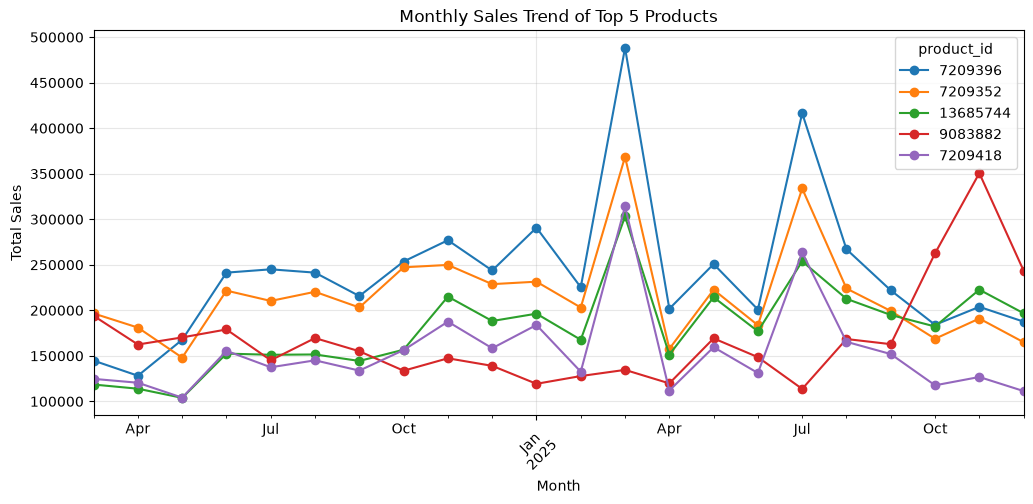

In [21]:
top5_ids = (
    product_summary.head(5).index.get_level_values("product_id")
)
top5_trend = product_sales_trend[top5_ids]
top5_trend.plot(
    figsize = (12,5),
    kind = "line",
    marker = "o"
)
plt.title("Monthly Sales Trend of Top 5 Products")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.savefig(
    "Top5_Product_Sales_Trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Store sales

In [22]:
display(df["store_selling"].describe())
print("Missing Values:", df["store_selling"].isna().sum())
print("Zero Store Records:", (df["store_selling"] == 0).sum())
display(df.groupby("channel")["store_selling"].describe())

count    6099.000000
mean      377.047057
std       273.435744
min         1.000000
25%       125.500000
50%       306.000000
75%       643.500000
max       855.000000
Name: store_selling, dtype: float64

Missing Values: 261
Zero Store Records: 0


,count,mean,std,min,25%,50%,75%,max
channel,,,,,,,,
instore,3180.0,582.034906,219.940746,1.0,502.75,635.0,733.25,855.0
online,2919.0,153.730387,88.692271,1.0,85.00,139.0,212.00,594.0


In [23]:
store_analysis = df.copy()
store_analysis["sales_per_store"] = (
    store_analysis["sales"] / store_analysis["store_selling"]
).round(4)
store_analysis["units_per_store"] = (
    store_analysis["units"] / store_analysis["store_selling"]
).round(4)
display(store_analysis[
    ["date", "product_name", "channel", "sales", "units", "store_selling", "sales_per_store", "units_per_store"]
])

,date,product_name,channel,sales,units,store_selling,sales_per_store,units_per_store
0,2024-03-02,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,instore,13258.29,4751.0,669.0,19.8181,7.1016
1,2024-03-02,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,online,1084.12,388.0,99.0,10.9507,3.9192
2,2024-03-02,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,instore,5567.62,1991.0,542.0,10.2724,3.6734
3,2024-03-02,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,online,383.84,138.0,59.0,6.5058,2.3390
4,2024-03-02,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,instore,14.00,5.0,3.0,4.6667,1.6667
...,...,...,...,...,...,...,...,...
6355,2025-12-27,TEMPTATIONS CREAMY SPOONS TASTY CHICKEN & CHEE...,online,669.75,134.0,60.0,11.1625,2.2333
6356,2025-12-27,TEMPTATIONS CREAMY SPOONS TASTY CHICKEN & SAVO...,instore,8841.66,1775.0,521.0,16.9706,3.4069
6357,2025-12-27,TEMPTATIONS CREAMY SPOONS TASTY CHICKEN & SAVO...,online,594.25,119.0,47.0,12.6436,2.5319
6358,2025-12-27,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CA...,instore,26011.06,2604.0,690.0,37.6972,3.7739


In [24]:
#Product Productivity
product_productivity = store_analysis.groupby(
    ["product_id", "product_name"]
).agg(
    avg_sales_per_store = ("sales_per_store", "mean"),
    avg_units_per_store = ("units_per_store", "mean"),
    record_count = ("sales_per_store", "count")
)
product_productivity = product_productivity.sort_values(
    by = "avg_sales_per_store",
    ascending = False
)
display(product_productivity.head(10))

,,avg_sales_per_store,avg_units_per_store,record_count
product_id,product_name,,,
9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 350G:TASTY CHICKEN:.:350 GRAM,44.568883,3.103126,192
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,40.941038,4.932137,192
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,40.363811,4.974593,192
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,37.492152,4.558644,192
10455188,TEMPTATIONS CAT TREAT HEARTY BEEF 350 GRAM:BEEF:.:350 GRAM,32.253520,2.245398,192
7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BEEF:.:180 GRAM,28.902792,3.534081,192
5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR 4X12G SACHETS:CHICKEN:.:4 PACK,24.066539,7.396319,192
2384320,PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 PACK,23.860652,2.000118,33
13685854,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN WHITEFISH 4X12GRAM:CHICKEN:.:4 PACK,22.000829,6.764186,192


C:\Users\liuc0\AppData\Local\Temp\ipykernel_17852\1207581956.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


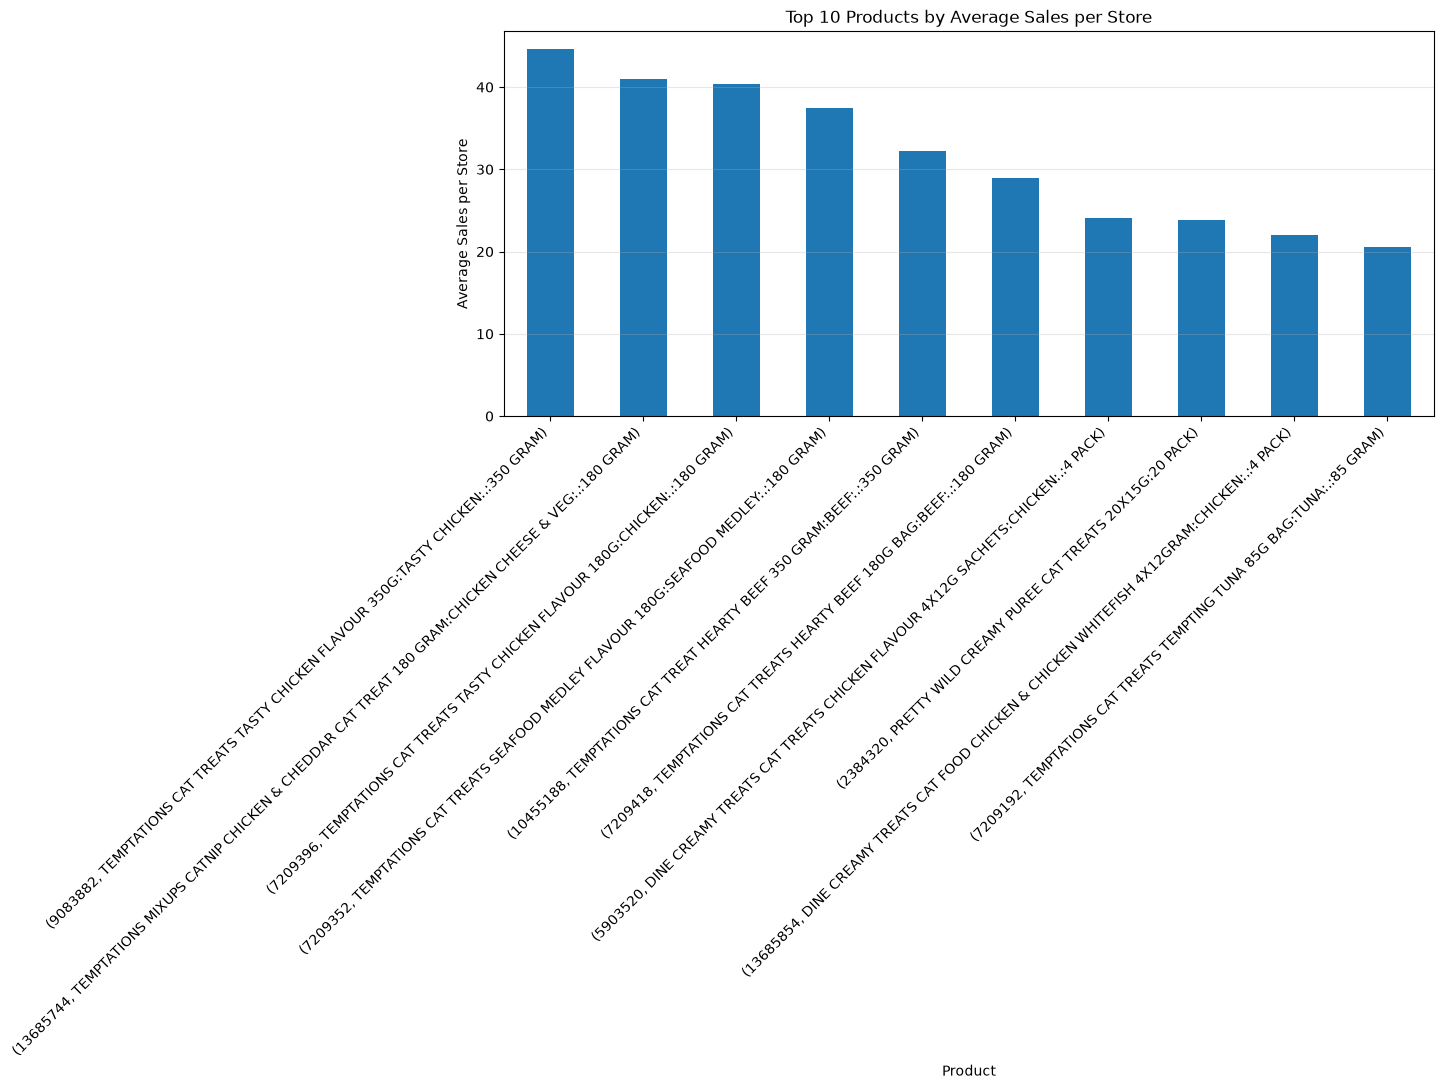

In [25]:
top10_productivity = product_productivity.head(10)

top10_productivity.plot(
    y= "avg_sales_per_store",
    kind = "bar",
    figsize = (12,5),
    legend = False
)
plt.title("Top 10 Products by Average Sales per Store")
plt.xlabel("Product")
plt.ylabel("Average Sales per Store")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "Top10_Product_Productivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
sales_table = product_summary.reset_index()
productivity_table = product_productivity.reset_index()
product_performance = pd.merge(
    sales_table,
    productivity_table[
        ["product_id", "product_name", "avg_sales_per_store"]
    ],
    on = ["product_id", "product_name"],
    how = "left"
)
display(product_performance.head(10))

,product_id,product_name,total_sales,total_units,record_count,sales_share,volumn_share,asp,avg_sales_per_store
0,7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,5297020.96,665875.0,192,8.6078,4.7244,7.95,40.363811
1,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,4755693.66,588920.0,192,7.7281,4.1784,8.08,37.492152
2,13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CA...,3968620.34,484695.0,192,6.4491,3.4389,8.19,40.941038
3,9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,3716446.26,259759.0,192,6.0393,1.8430,14.31,44.568883
4,7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BE...,3393133.48,426454.0,192,5.5139,3.0257,7.96,28.902792
5,5903520,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR ...,2732688.04,849299.0,192,4.4407,6.0257,3.22,24.066539
6,5903522,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FL...,2681787.84,833640.0,192,4.3580,5.9146,3.22,20.262365
7,7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,2571399.65,560921.0,192,4.1786,3.9797,4.58,20.172784
8,6722290,DINE CREAMY TREATS CAT TREATS TUNA & PRAWN FLA...,2520891.49,787024.0,192,4.0965,5.5839,3.20,19.303588
9,13685854,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,2514794.49,780779.0,192,4.0866,5.5396,3.22,22.000829


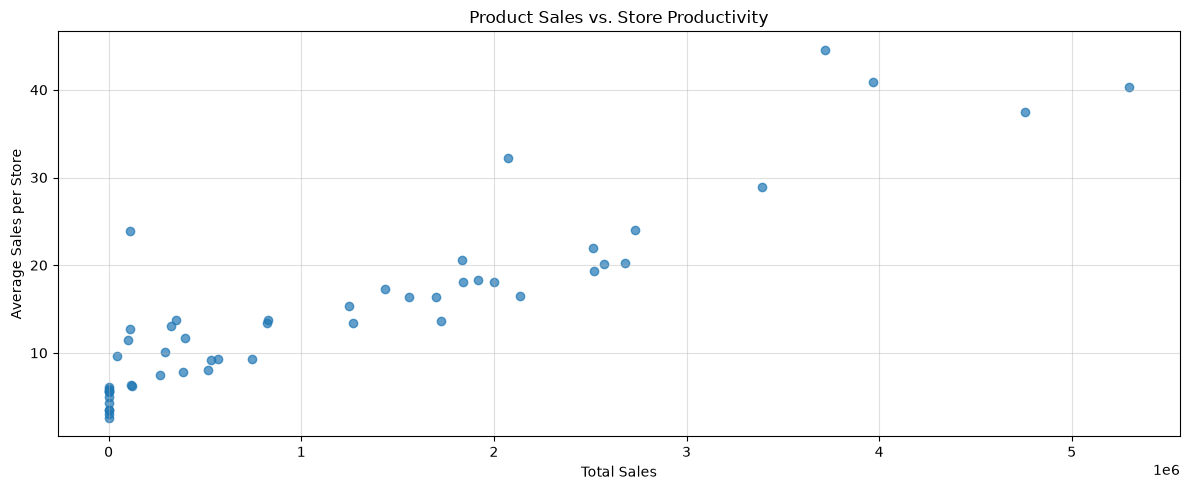

In [27]:
plt.figure(figsize=(12,5))
plt.scatter(
    product_performance["total_sales"],
    product_performance["avg_sales_per_store"],
    alpha=0.7
)
plt.title("Product Sales vs. Store Productivity")
plt.xlabel("Total Sales")
plt.ylabel("Average Sales per Store")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(
    "Product_Sales_vs_Productivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Data Quality Check

In [28]:
numeric_cols = ["sales", "units", "store_selling"]
negative_counts = df[numeric_cols].lt(0).sum()
display(negative_counts)
negative_rows = df[df[numeric_cols].lt(0).any(axis=1)]
display(negative_rows)
zero_sales_positive_units = df[
    (df["sales"] == 0) & (df["units"] > 0)
]
print("Zero sales with positive units:", len(zero_sales_positive_units))

sales            2
units            2
store_selling    0
dtype: int64

,date,product_id,product_name,channel,sales,units,store_selling,month
2706,2024-12-14,8480336,FUSSY CAT GRAIN FREE CRUNCHERS ADULT CAT TREAT...,instore,-3.9,-1.0,1.0,2024-12
3310,2025-02-15,8480336,FUSSY CAT GRAIN FREE CRUNCHERS ADULT CAT TREAT...,instore,-7.8,-2.0,1.0,2025-02


Zero sales with positive units: 0


In [29]:
#Detect Outlier using IQR
Q1 = df["sales"].quantile(0.25)
Q3 = df["sales"].quantile(0.75)
IQR = Q3 - Q1
lb = Q1-1.5*IQR
ub = Q3+1.5*IQR
sales_outliers = df[
    (df["sales"]<lb) | (df["sales"]>ub)
]
print("Lower bound and upper bound:", lb.round(3), ub.round(3))
print("Number of outliers:", len(sales_outliers))
display(sales_outliers.head(10))


Lower bound and upper bound: -18950.74 34712.98
Number of outliers: 317


,date,product_id,product_name,channel,sales,units,store_selling,month
44,2024-03-02,7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,instore,44397.09,11125.0,835.0,2024-03
124,2024-03-09,7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,instore,35131.63,3912.0,801.0,2024-03
126,2024-03-09,9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,34966.67,2508.0,504.0,2024-03
152,2024-03-16,5903522,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FL...,instore,35293.72,11049.0,831.0,2024-03
190,2024-03-16,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,38476.03,4281.0,797.0,2024-03
196,2024-03-16,9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,37846.20,2712.0,502.0,2024-03
262,2024-03-23,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,43743.33,4869.0,803.0,2024-03
268,2024-03-23,9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,41285.86,2961.0,475.0,2024-03
324,2024-03-30,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,43088.11,4809.0,804.0,2024-03
330,2024-03-30,9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,38696.46,2782.0,464.0,2024-03


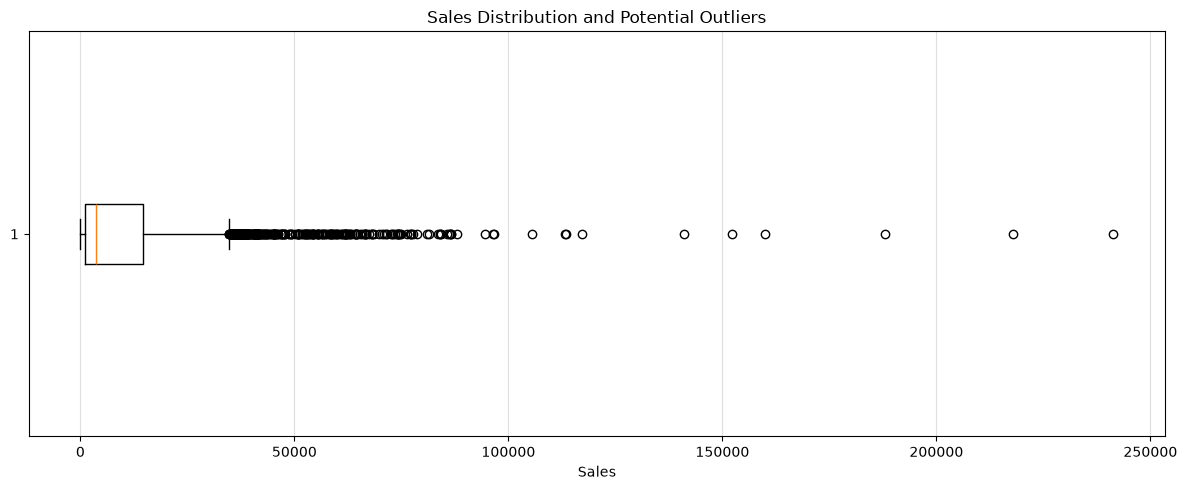

In [30]:
#boxplot

plt.figure(figsize=(12,5))
plt.boxplot(
    df["sales"].dropna(),
    orientation = "horizontal"
)
plt.title("Sales Distribution and Potential Outliers")
plt.xlabel("Sales")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.savefig(
    "Sales_Outlier_Boxplot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
#Outlier Analysis
outlier_analysis = df.copy()
outlier_analysis["is_outlier"] = (
    (outlier_analysis["sales"]<lb)|(outlier_analysis["sales"]>ub)
)
display(
    outlier_analysis[
        ["product_name", "channel", "sales", "is_outlier"]
    ].head(10)
)
display(outlier_analysis["is_outlier"].value_counts())

#Compare sales average w/ & w/o outliers 
mean_all = outlier_analysis["sales"].mean()
mean_without_outliers = outlier_analysis.loc[~outlier_analysis["is_outlier"], "sales"].mean()
mean_diff = (
    (mean_all-mean_without_outliers)/mean_without_outliers*100
)

sales_mean = df["sales"].mean()
sales_median = df["sales"].median()
print("Mean:", round(sales_mean, 2))
print("Median:", round(sales_median, 2))
print("Mean sales with outliers:", round(mean_all, 2))
print("Mean sales without outliers:", round(mean_without_outliers, 2))
print("Percentage difference:", round(mean_diff, 2), "%")

,product_name,channel,sales,is_outlier
0,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,instore,13258.29,False
1,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,online,1084.12,False
2,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,instore,5567.62,False
3,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,online,383.84,False
4,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,instore,14.00,False
5,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,online,NaN,False
6,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,instore,32212.85,False
7,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,online,978.00,False
8,DINE CREAMY TREATS CAT FOOD SEAFOOD & TUNA SAL...,instore,25508.92,False
9,DINE CREAMY TREATS CAT FOOD SEAFOOD & TUNA SAL...,online,663.68,False


is_outlier
False    6043
True      317
Name: count, dtype: int64

Mean: 10089.76
Median: 3564.94
Mean sales with outliers: 10089.76
Mean sales without outliers: 7737.1
Percentage difference: 30.41 %


In [32]:
#outliers by channel
channel_outlier = df.copy()
channel_outlier["Q1"] = (
    channel_outlier.groupby("channel")["sales"].transform(lambda x: x.quantile(0.25))
)
channel_outlier["Q3"] = (
    channel_outlier.groupby("channel")["sales"].transform(lambda x: x.quantile(0.75))
)
channel_outlier["IQR"] = (
    channel_outlier["Q3"] - channel_outlier["Q1"]
)
channel_outlier["lb"]=(
    channel_outlier["Q1"]-1.5*channel_outlier["IQR"]
)
channel_outlier["ub"]=(
    channel_outlier["Q3"]+1.5*channel_outlier["IQR"]
)
channel_outlier["is_outlier"] = (
    (channel_outlier["sales"] < channel_outlier["lb"])|
    (channel_outlier["sales"] > channel_outlier["ub"])
)
channel_bounds = channel_outlier.groupby("channel")[["lb", "ub"]].first().round(3)
print("Lower and upper bounds by channel:")
print(channel_bounds)
display(channel_outlier.groupby("channel")["is_outlier"].sum())
print("Total number of outliers for two channels:",channel_outlier["is_outlier"].sum())

Lower and upper bounds by channel:
                lb         ub
channel                      
instore -16818.388  48733.572
online   -1516.860   4489.060


channel
instore    136
online     137
Name: is_outlier, dtype: int64

Total number of outliers for two channels: 273


In [33]:
#extract outlier rows
channel_outlier_rows = channel_outlier[channel_outlier["is_outlier"]]
display(channel_outlier_rows[["date", "product_id", "product_name", "channel", "sales", "lb", "ub"]].head(10))

,date,product_id,product_name,channel,sales,lb,ub
592,2024-04-27,7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,instore,50186.20,-16818.3875,48733.5725
826,2024-05-25,7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,instore,51027.37,-16818.3875,48733.5725
1060,2024-06-22,7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,instore,50930.26,-16818.3875,48733.5725
1124,2024-06-29,7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BE...,instore,55645.82,-16818.3875,48733.5725
1126,2024-06-29,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,81095.70,-16818.3875,48733.5725
1127,2024-06-29,7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,online,5585.15,-1516.8600,4489.0600
1130,2024-06-29,7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,instore,94567.49,-16818.3875,48733.5725
1131,2024-06-29,7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,online,6265.28,-1516.8600,4489.0600
1138,2024-06-29,13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CA...,instore,57582.14,-16818.3875,48733.5725
1242,2024-07-13,7209170,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,instore,48745.08,-16818.3875,48733.5725


In [34]:
#Comparison
outlier_comparison = df.copy()
outlier_comparison["overall_outlier"] = outlier_analysis["is_outlier"]
outlier_comparison["channel_outlier"] = channel_outlier["is_outlier"]
display(outlier_comparison[["product_name", "channel", "sales", "overall_outlier", "channel_outlier"]].head(10))

comparison_summary = outlier_comparison.groupby("channel").agg(
    overall_count=("overall_outlier", "sum"),
    channel_count=("channel_outlier", "sum"),
    total_records=("sales", "count")
)

comparison_summary["channel_outlier_rate"] = (
    comparison_summary["channel_count"]/comparison_summary["total_records"]*100
).round(2)

# 显示比较结果
display(comparison_summary)

,product_name,channel,sales,overall_outlier,channel_outlier
0,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,instore,13258.29,False,False
1,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,online,1084.12,False,False
2,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,instore,5567.62,False,False
3,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,online,383.84,False,False
4,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,instore,14.00,False,False
5,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,online,NaN,False,False
6,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,instore,32212.85,False,False
7,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,online,978.00,False,False
8,DINE CREAMY TREATS CAT FOOD SEAFOOD & TUNA SAL...,instore,25508.92,False,False
9,DINE CREAMY TREATS CAT FOOD SEAFOOD & TUNA SAL...,online,663.68,False,False


,overall_count,channel_count,total_records,channel_outlier_rate
channel,,,,
instore,317,136,3180,4.28
online,0,137,2919,4.69


In [35]:
#Find records with different outlier classifications
different_results = outlier_comparison[
    outlier_comparison["overall_outlier"] != outlier_comparison["channel_outlier"]
]
print("number of different classification records:", len(different_results))
display(
    different_results[
        ["date", "product_name", "channel", "sales", "overall_outlier", "channel_outlier"]
    ].head(20)
)

#export result
outlier_comparison.to_csv(
    "Outlier_comparison.csv"
)
comparison_summary.to_csv(
    "Outlier_Summary.csv"
)
different_results.to_csv(
    "different_outlier_result.csv"
)

number of different classification records: 318


,date,product_name,channel,sales,overall_outlier,channel_outlier
44,2024-03-02,TEMPTATIONS CAT TREAT TANTALISING TURKEY 85G B...,instore,44397.09,True,False
124,2024-03-09,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 1...,instore,35131.63,True,False
126,2024-03-09,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,34966.67,True,False
152,2024-03-16,DINE CREAMY TREATS CAT TREATS TUNA & SALMON FL...,instore,35293.72,True,False
190,2024-03-16,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,38476.03,True,False
196,2024-03-16,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,37846.20,True,False
262,2024-03-23,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,43743.33,True,False
268,2024-03-23,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,41285.86,True,False
324,2024-03-30,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR ...,instore,43088.11,True,False
330,2024-03-30,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 3...,instore,38696.46,True,False


Correlation Analysis

In [36]:
#correlation
corr_data = df[["sales","units","store_selling"]]
corr_matrix = corr_data.corr()
display(corr_matrix)

,sales,units,store_selling
sales,1.000000,0.831739,0.710621
units,0.831739,1.000000,0.741565
store_selling,0.710621,0.741565,1.000000


In [37]:
channel_corr_data = (
    df.groupby("channel")[["sales","units","store_selling"]].corr()
)
display(channel_corr_data)

sales     units  store_selling
channel                                                 
instore sales          1.000000  0.754270       0.544907
        units          0.754270  1.000000       0.595990
        store_selling  0.544907  0.595990       1.000000
online  sales          1.000000  0.735394       0.775307
        units          0.735394  1.000000       0.887869
        store_selling  0.775307  0.887869       1.000000

Pivot Table

In [38]:
monthly_pivot = pd.pivot_table(
    df,
    values="sales",
    index="month",
    columns="channel",
    aggfunc="sum"
)
monthly_pivot["total_sales"] = monthly_pivot.sum(axis=1)
monthly_pivot["online_share"] = ((monthly_pivot["online"] / monthly_pivot["total_sales"]) * 100).round(2)
monthly_pivot["online_share_change"] = (
    monthly_pivot["online_share"].diff()
).round(2)
monthly_pivot["online_share_percentage_change"] = (
    monthly_pivot["online_share"].pct_change()*100
).round(2)

display(monthly_pivot.head(5))

channel,instore,online,total_sales,online_share,online_share_change,online_share_percentage_change
month,,,,,,
2024-03,2572177.38,181754.21,2753931.59,6.60,NaN,NaN
2024-04,2191097.54,155722.28,2346819.82,6.64,0.04,0.61
2024-05,2296462.73,176015.08,2472477.81,7.12,0.48,7.23
2024-06,2738916.55,211017.92,2949934.47,7.15,0.03,0.42
2024-07,2352364.68,187581.94,2539946.62,7.39,0.24,3.36


CASE STUDY PART

Part1. Category & Brand Performance

In [39]:
#1. Total category sales and YoY growth
display(monthly_summary)

,total_sales,total_units,record_count,sales_mom,units_mom,sales_yoy,units_yoy,asp
month,,,,,,,,
2024-03,2753931.59,616770.0,310,NaN,NaN,NaN,NaN,4.465087
2024-04,2346819.82,509999.0,244,-14.782930,-17.311315,NaN,NaN,4.601617
2024-05,2472477.81,600643.0,233,5.354394,17.773368,NaN,NaN,4.116385
2024-06,2949934.47,648891.0,288,19.310857,8.032725,NaN,NaN,4.546117
2024-07,2539946.62,573711.0,231,-13.898202,-11.585921,NaN,NaN,4.427223
2024-08,3004155.81,685743.0,286,18.276336,19.527602,NaN,NaN,4.380877
2024-09,2355394.03,515620.0,259,-21.595477,-24.808565,NaN,NaN,4.568081
2024-10,2672109.63,621784.0,272,13.446396,20.589581,NaN,NaN,4.297489
2024-11,3084492.79,747347.0,336,15.432868,20.193990,NaN,NaN,4.127257


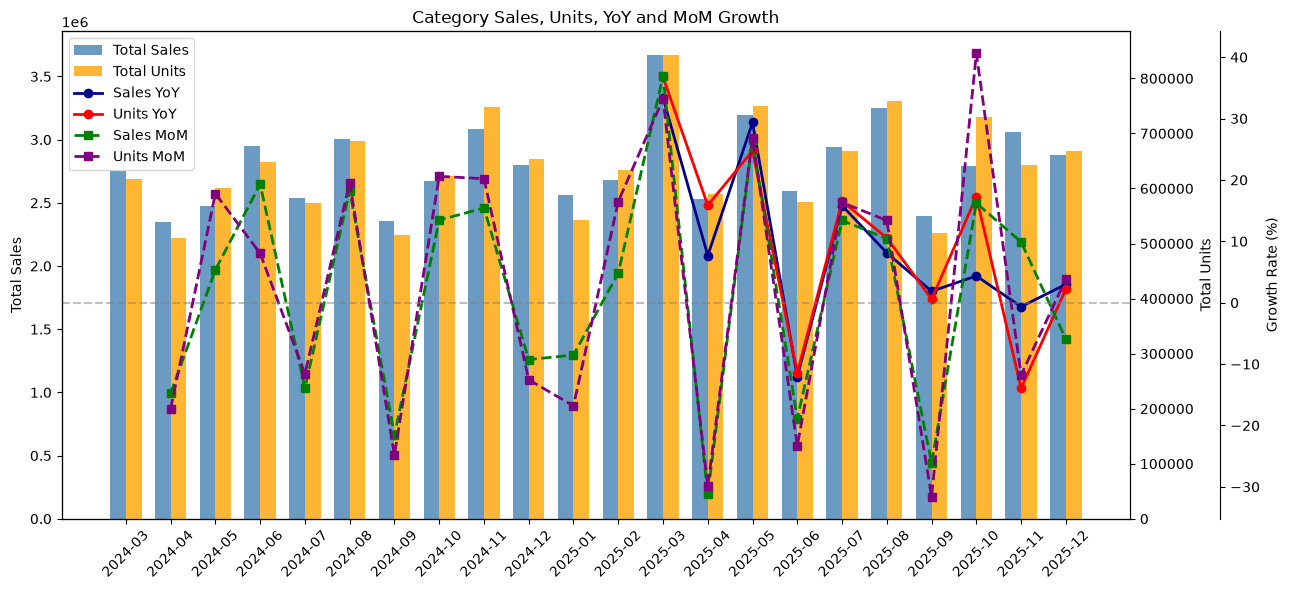

,sales_yoy,units_yoy,sales_mom,units_mom,yoy_gap_pp,mom_gap_pp
month,,,,,,
2024-03,NaN,NaN,NaN,NaN,NaN,NaN
2024-04,NaN,NaN,-14.78,-17.31,NaN,2.53
2024-05,NaN,NaN,5.35,17.77,NaN,-12.42
2024-06,NaN,NaN,19.31,8.03,NaN,11.28
2024-07,NaN,NaN,-13.90,-11.59,NaN,-2.31
2024-08,NaN,NaN,18.28,19.53,NaN,-1.25
2024-09,NaN,NaN,-21.60,-24.81,NaN,3.21
2024-10,NaN,NaN,13.45,20.59,NaN,-7.14
2024-11,NaN,NaN,15.43,20.19,NaN,-4.76


In [40]:
#2. Volume vs value dynamics
plot_data = monthly_summary[["total_sales", "total_units", "sales_yoy", "units_yoy", "sales_mom", "units_mom"]].copy()
x = np.arange(len(plot_data))
width = 0.35
fig, ax1 = plt.subplots(figsize=(13, 6))
bars1 = ax1.bar(
    x - width / 2,
    plot_data["total_sales"],
    width,
    label="Total Sales",
    color="steelblue",
    alpha=0.8
)
ax1.set_ylabel("Total Sales")
ax2 = ax1.twinx()
bars2 = ax2.bar(
    x + width / 2,
    plot_data["total_units"],
    width,
    label="Total Units",
    color="orange",
    alpha=0.8
)
ax2.set_ylabel("Total Units")
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 65))
line1, = ax3.plot(
    x,
    plot_data["sales_yoy"],
    marker="o",
    color="darkblue",
    linewidth=2,
    label="Sales YoY (%)"
)
line2, = ax3.plot(
    x,
    plot_data["units_yoy"],
    marker="o",
    color="red",
    linewidth=2,
    label="Units YoY (%)"
)
line3, = ax3.plot(
    x,
    plot_data["sales_mom"],
    marker="s",
    color="green",
    linestyle="--",
    linewidth=2,
    label="Sales MoM (%)"
)
line4, = ax3.plot(
    x,
    plot_data["units_mom"],
    marker="s",
    color="purple",
    linestyle="--",
    linewidth=2,
    label="Units MoM (%)"
)
ax3.set_ylabel("Growth Rate (%)")
ax3.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_data.index.astype(str), rotation=45)
plt.title("Category Sales, Units, YoY and MoM Growth")
ax1.legend(
    [bars1, bars2, line1, line2, line3, line4],
    ["Total Sales", "Total Units", "Sales YoY", "Units YoY", "Sales MoM", "Units MoM"],
    loc="upper left"
)
fig.tight_layout()
plt.show()

#Growth Comparison
growth_comparison = monthly_summary[["sales_yoy", "units_yoy", "sales_mom", "units_mom"]].copy()
growth_comparison["yoy_gap_pp"] = (growth_comparison["sales_yoy"]-growth_comparison["units_yoy"])
growth_comparison["mom_gap_pp"] = (growth_comparison["sales_mom"]-growth_comparison["units_mom"])
display(growth_comparison.round(2))


In [41]:
#3. Brand shares and share changes
display(df[["product_name", "product_id"]].drop_duplicates().sort_values("product_name"))
brands = ["APPLAWS", "CHURU", "DINE", "FELIX", "FUSSY CAT", "MEAT MATES", "PRETTY WILD", "PRIME PANTRY", "PURR", "RUFUS & COCO", "TEMPTATIONS"]
df["brand"] = df["product_name"].apply(
    lambda name: next((brand for brand in brands if name.startswith(brand)),"Unknown")
)
display(df["brand"].value_counts())
print("brand of records not identified number:", df["brand"].isna().sum())

brand_monthly = df.groupby(["month", "brand"])["sales"].sum().reset_index()
brand_monthly["category_sales"] = brand_monthly.groupby("month")["sales"].transform("sum")
brand_monthly["market_share"] = (
    brand_monthly["sales"]/brand_monthly["category_sales"]*100
)
display(brand_monthly)

brand_share = brand_monthly.pivot(
    index="month",
    columns="brand",
    values="market_share"
)
display(brand_share.round(5))

brand_share_change = brand_share.diff()
display(brand_share_change.round(5))

,product_name,product_id
0,APPLAWS CAT TREAT TUNA LOIN 30G:TUNA LOINS:.:3...,3504926
1736,APPLAWS CHICKEN PUREE CAT TREAT 4X15GRAM:4 PACK,16957526
2,APPLAWS MACKEREL LOIN CAT TREAT 30 GRAM:MACKER...,4643054
4,APPLAWS NATURAL CAT TREAT SALMON FILLETS 25GRA...,6715172
5158,CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM...,2387538
5160,CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 5...,2387544
6,DINE CREAMY TREATS CAT FOOD CHICKEN & CHICKEN ...,13685854
8,DINE CREAMY TREATS CAT FOOD SEAFOOD & TUNA SAL...,13685920
10,DINE CREAMY TREATS CAT TREATS CHICKEN FLAVOUR ...,5903520
12,DINE CREAMY TREATS CAT TREATS MIXED SEAFOOD FL...,7627602


brand
TEMPTATIONS     2542
DINE            1344
FELIX            548
APPLAWS          542
FUSSY CAT        514
PURR             472
PRIME PANTRY     256
CHURU             68
MEAT MATES        36
PRETTY WILD       34
RUFUS & COCO       4
Name: count, dtype: int64

brand of records not identified number: 0


,month,brand,sales,category_sales,market_share
0,2024-03,APPLAWS,119943.03,2753931.59,4.355338
1,2024-03,DINE,773389.54,2753931.59,28.083106
2,2024-03,FUSSY CAT,247303.18,2753931.59,8.980004
3,2024-03,MEAT MATES,45.00,2753931.59,0.001634
4,2024-03,PRIME PANTRY,40842.30,2753931.59,1.483054
...,...,...,...,...,...
159,2025-12,FELIX,137232.89,2882186.21,4.761417
160,2025-12,FUSSY CAT,158314.26,2882186.21,5.492853
161,2025-12,PRETTY WILD,32901.06,2882186.21,1.141531
162,2025-12,PURR,152953.24,2882186.21,5.306848


brand,APPLAWS,CHURU,DINE,FELIX,FUSSY CAT,MEAT MATES,PRETTY WILD,PRIME PANTRY,PURR,RUFUS & COCO,TEMPTATIONS
month,,,,,,,,,,,
2024-03,4.35534,NaN,28.08311,NaN,8.98000,0.00163,NaN,1.48305,4.83680,0.00004,52.26002
2024-04,4.11206,NaN,29.67378,NaN,8.62585,0.00228,NaN,1.39328,4.58295,NaN,51.60979
2024-05,4.00391,NaN,29.93641,NaN,8.99382,0.00097,NaN,1.24211,3.87347,NaN,51.94931
2024-06,4.39223,NaN,24.05135,0.00015,8.63059,0.00006,NaN,1.44276,4.61233,NaN,56.87053
2024-07,3.41971,NaN,28.31856,0.00018,8.71443,0.00094,NaN,1.55533,4.16281,NaN,53.82805
2024-08,3.65378,NaN,25.07388,NaN,7.89892,0.00070,NaN,1.50598,4.61586,NaN,57.25088
2024-09,4.36400,NaN,27.79046,1.22556,8.07129,0.00002,NaN,0.30910,4.64090,NaN,53.59868
2024-10,4.02933,NaN,21.94474,3.79131,6.54064,NaN,NaN,0.00607,3.57238,NaN,60.11553
2024-11,4.20806,NaN,25.90782,4.32915,6.75798,NaN,NaN,0.00097,3.95300,0.00032,54.84270


brand,APPLAWS,CHURU,DINE,FELIX,FUSSY CAT,MEAT MATES,PRETTY WILD,PRIME PANTRY,PURR,RUFUS & COCO,TEMPTATIONS
month,,,,,,,,,,,
2024-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-04,-0.24327,NaN,1.59067,NaN,-0.35415,0.00064,NaN,-0.08977,-0.25385,NaN,-0.65022
2024-05,-0.10815,NaN,0.26264,NaN,0.36797,-0.00131,NaN,-0.15117,-0.70949,NaN,0.33952
2024-06,0.38831,NaN,-5.88506,NaN,-0.36323,-0.00091,NaN,0.20065,0.73887,NaN,4.92122
2024-07,-0.97252,NaN,4.26721,0.00002,0.08384,0.00088,NaN,0.11256,-0.44953,NaN,-3.04247
2024-08,0.23407,NaN,-3.24468,NaN,-0.81551,-0.00025,NaN,-0.04934,0.45306,NaN,3.42283
2024-09,0.71021,NaN,2.71658,NaN,0.17238,-0.00068,NaN,-1.19688,0.02503,NaN,-3.65220
2024-10,-0.33467,NaN,-5.84572,2.56575,-1.53065,NaN,NaN,-0.30303,-1.06852,NaN,6.51684
2024-11,0.17873,NaN,3.96308,0.53784,0.21734,NaN,NaN,-0.00510,0.38062,NaN,-5.27282


In [42]:
#4. Which brands are winning and losing
brand_share_yoy = brand_share.diff(12)
display(brand_share_yoy.loc["2025-03":"2025-12"].mean().sort_values(ascending=False).round(2))

brand
FELIX           2.22
TEMPTATIONS     1.15
PURR            0.19
APPLAWS         0.13
PRIME PANTRY   -1.05
FUSSY CAT      -2.24
DINE           -2.73
CHURU            NaN
MEAT MATES       NaN
PRETTY WILD      NaN
RUFUS & COCO     NaN
dtype: float64

In [43]:
#5. What products are winning and losing
display(product_summary.head(5))
display(product_monthly)

product_monthly_sales = df.pivot_table(
    index="month",
    columns="product_id",
    values="sales",
    aggfunc="sum"
)

sales_2024 = product_monthly_sales.loc["2024-03":"2024-12"].sum()
sales_2025 = product_monthly_sales.loc["2025-03":"2025-12"].sum()

product_performance = pd.DataFrame({"sales_2024": sales_2024, "sales_2025": sales_2025})

product_performance["sales_change"] = (product_performance["sales_2025"]-product_performance["sales_2024"])
min_base_sales = 10
product_performance["growth_pct"] = np.where(
    product_performance["sales_2024"] >= min_base_sales,
    product_performance["sales_change"]/product_performance["sales_2024"]*100,
    np.nan
)
product_analysis = product_performance.sort_values("sales_change", ascending=False)

display(product_analysis.head(10).round(2))
display(product_analysis.tail(10).round(2))

,,total_sales,total_units,record_count,sales_share,volumn_share,asp
product_id,product_name,,,,,,
7209396,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 180G:CHICKEN:.:180 GRAM,5297020.96,665875.0,192,8.6078,4.7244,7.95
7209352,TEMPTATIONS CAT TREATS SEAFOOD MEDLEY FLAVOUR 180G:SEAFOOD MEDLEY:.:180 GRAM,4755693.66,588920.0,192,7.7281,4.1784,8.08
13685744,TEMPTATIONS MIXUPS CATNIP CHICKEN & CHEDDAR CAT TREAT 180 GRAM:CHICKEN CHEESE & VEG:.:180 GRAM,3968620.34,484695.0,192,6.4491,3.4389,8.19
9083882,TEMPTATIONS CAT TREATS TASTY CHICKEN FLAVOUR 350G:TASTY CHICKEN:.:350 GRAM,3716446.26,259759.0,192,6.0393,1.8430,14.31
7209418,TEMPTATIONS CAT TREATS HEARTY BEEF 180G BAG:BEEF:.:180 GRAM,3393133.48,426454.0,192,5.5139,3.0257,7.96


total_sales  total_units
month   product_id                          
2024-03 3504926        85093.25      32979.0
        4643054        34676.16      13416.0
        5903520       132955.68      37726.0
        5903522       137430.06      38989.0
        5903570        83141.68      23662.0
...                         ...          ...
2025-12 15581366       39776.97      18344.0
        16957526           2.36          3.0
        16965870       41835.40       8400.0
        16965892          42.50         10.0
        16965914       43899.09       8815.0

[780 rows x 2 columns]

,sales_2024,sales_2025,sales_change,growth_pct
product_id,,,,
13685744,1495921.62,2108733.79,612812.17,40.97
7209396,2158380.11,2622528.93,464148.82,21.50
16965870,198420.73,530877.47,332456.74,167.55
16965914,202232.10,534344.05,332111.95,164.22
9083882,1595396.81,1873932.54,278535.73,17.46
15581366,113144.29,381359.81,268215.52,237.06
15581338,104139.64,359939.65,255800.01,245.63
7601684,102343.51,353304.47,250960.96,245.21
7209418,1423362.40,1653300.57,229938.17,16.15


,sales_2024,sales_2025,sales_change,growth_pct
product_id,,,,
8475978,878731.15,815666.98,-63064.17,-7.18
5903522,1268372.73,1203680.60,-64692.13,-5.10
6722290,1207401.32,1113912.80,-93488.52,-7.74
7209170,1240664.95,1134792.52,-105872.43,-8.53
8479614,116042.90,28.08,-116014.82,-99.98
8479570,122872.36,50.76,-122821.60,-99.96
8555416,1034234.81,907897.36,-126337.45,-12.22
8480336,294392.30,38.80,-294353.50,-99.99
7209098,324531.04,11.00,-324520.04,-100.00


Part2. Drivers of Growth

In [44]:
#1. How much growth is driven by units vs price/mix
period_2024 = monthly_summary.loc["2024-03":"2024-12"]
period_2025 = monthly_summary.loc["2025-03":"2025-12"]
sales_0 = period_2024["total_sales"].sum()
sales_1 = period_2025["total_sales"].sum()
units_0 = period_2024["total_units"].sum()
units_1 = period_2025["total_units"].sum()
asp_0 = sales_0 / units_0
asp_1 = sales_1 / units_1
volume_effect = (units_1 - units_0) * asp_0
price_mix_effect = units_1 * (asp_1 - asp_0)
total_growth = sales_1 - sales_0

growth_drivers = pd.DataFrame({
    "Effect": ["Volume Effect", "Price/Mix Effect", "Total Growth"],
    "Sales Change": [volume_effect, price_mix_effect, total_growth],
    "Contribution (%)": [
        volume_effect / total_growth * 100,
        price_mix_effect / total_growth * 100,
        100
    ]
})

display(growth_drivers.round(2))

,Effect,Sales Change,Contribution (%)
0,Volume Effect,2489400.57,106.41
1,Price/Mix Effect,-149989.29,-6.41
2,Total Growth,2339411.28,100.00


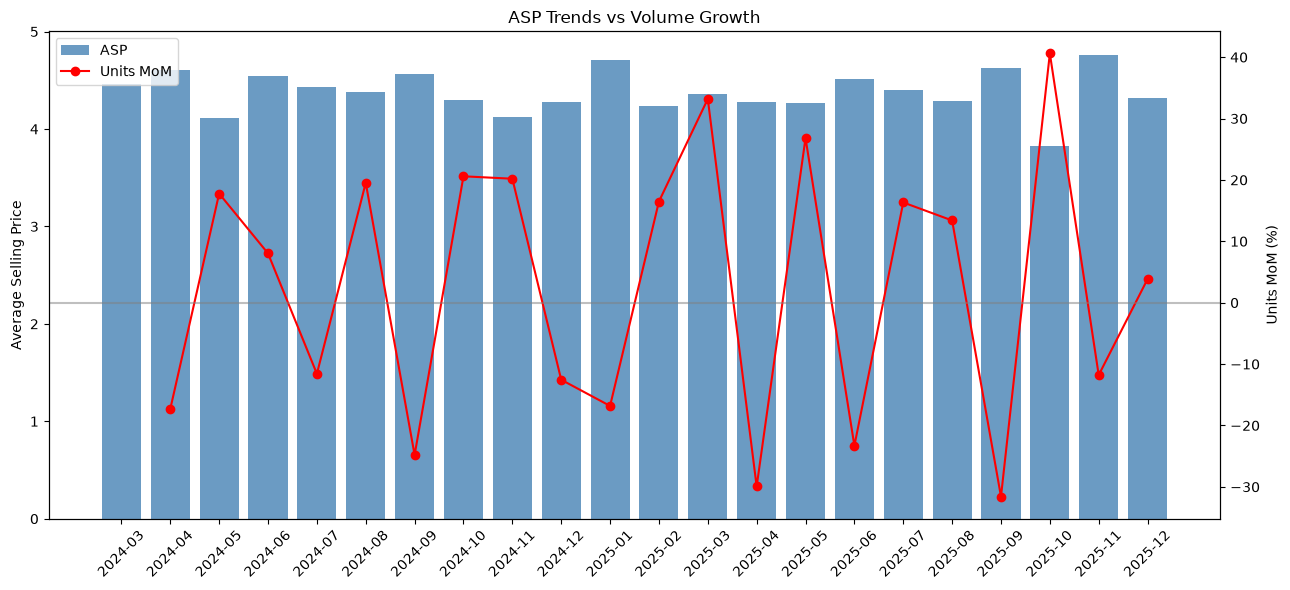

,total_sales,total_units,record_count,sales_mom,units_mom,sales_yoy,units_yoy,asp,asp_mom,asp_yoy
month,,,,,,,,,,
2024-05,2472477.81,600643.0,233,5.35,17.77,NaN,NaN,4.12,-10.54,NaN
2024-08,3004155.81,685743.0,286,18.28,19.53,NaN,NaN,4.38,-1.05,NaN
2024-10,2672109.63,621784.0,272,13.45,20.59,NaN,NaN,4.30,-5.92,NaN
2024-11,3084492.79,747347.0,336,15.43,20.19,NaN,NaN,4.13,-3.96,NaN
2025-02,2682929.01,633175.0,258,4.81,16.48,NaN,NaN,4.24,-10.02,NaN
2025-05,3198350.77,749282.0,318,26.56,26.81,29.36,24.75,4.27,-0.20,3.70
2025-07,2941707.07,668537.0,248,13.41,16.33,15.82,16.53,4.40,-2.51,-0.61
2025-08,3248160.39,758083.0,312,10.42,13.39,8.12,10.55,4.28,-2.63,-2.20
2025-10,2788600.26,729161.0,274,16.23,40.60,4.36,17.27,3.82,-17.33,-11.01


,asp_mom,units_mom
asp_mom,1.000,-0.552
units_mom,-0.552,1.000


In [45]:
2. #The role of promotion activity (hint: examine average selling price trends)

monthly_summary["asp_mom"] = monthly_summary["asp"].pct_change(fill_method=None) * 100
monthly_summary["asp_yoy"] = monthly_summary["asp"].pct_change(periods=12, fill_method=None) * 100

plot_data = monthly_summary[["asp", "units_mom"]].copy()
x = np.arange(len(plot_data))
fig, ax1 = plt.subplots(figsize=(13, 6))
bars = ax1.bar(
    x, plot_data["asp"],
    color="steelblue", alpha=0.8, label="ASP"
)
ax1.set_ylabel("Average Selling Price")
ax2 = ax1.twinx()
line, = ax2.plot(
    x, plot_data["units_mom"],
    marker="o", color="red", label="Units MoM (%)"
)
ax2.set_ylabel("Units MoM (%)")
ax2.axhline(0, color="gray", alpha=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_data.index.astype(str), rotation=45)
ax1.legend(
    [bars, line],
    ["ASP", "Units MoM"],
    loc="upper left"
)
plt.title("ASP Trends vs Volume Growth")
fig.tight_layout()
plt.show()


promotion_signal = monthly_summary[(monthly_summary["asp_mom"] < 0) & (monthly_summary["units_mom"] > 0)]
[["asp", "asp_mom", "total_units", "units_mom"]]
display(promotion_signal.round(2))


asp_volume_corr = monthly_summary[["asp_mom", "units_mom"]].corr()
display(asp_volume_corr.round(3))

In [46]:
#3. The role of innovation / new product development (NPD)
product_launch = (
    df.groupby(["product_id", "product_name"])["month"].min().reset_index(name="first_seen")
)

new_products = product_launch[
    product_launch["first_seen"] >= pd.Period("2025-03")
]

display(new_products.sort_values("first_seen"))
print("Number of potential NPD products:", len(new_products))

npd_monthly = df.merge(
    new_products[["product_id", "first_seen"]],
    on="product_id", how="inner"
)
npd_monthly = npd_monthly.groupby(
    ["product_id", "product_name", "first_seen", "month"]
)["sales"].sum().reset_index()
npd_monthly["months_since_launch"] = (
    (npd_monthly["month"].dt.year - npd_monthly["first_seen"].dt.year) * 12
    + npd_monthly["month"].dt.month - npd_monthly["first_seen"].dt.month
)
npd_lifecycle = npd_monthly.pivot_table(
    index=["product_id", "product_name", "first_seen"],
    columns="months_since_launch",
    values="sales",
    aggfunc="sum"
)
display(npd_lifecycle.round(2))


npd_contribution = new_products.merge(
    product_performance[["sales_2025", "sales_change"]].reset_index(),
    on="product_id",
    how="left"
)
npd_contribution["growth_contribution_pct"] = (npd_contribution["sales_change"] / total_growth * 100)
display(
    npd_contribution.sort_values("sales_change", ascending=False).round(2)
)

print("Total NPD Sales Growth:", round(npd_contribution["sales_change"].sum(), 2))
print(
    "NPD Contribution to Category Growth (%):",
    round(npd_contribution["sales_change"].sum() / total_growth * 100, 2)
)

npd_monthly_total = (npd_monthly.groupby("month")["sales"].sum())
npd_monthly_share = pd.DataFrame({
    "npd_sales": npd_monthly_total,
    "category_sales": monthly_summary["total_sales"]
}).dropna()
npd_monthly_share["npd_share_pct"] = (
    npd_monthly_share["npd_sales"]/npd_monthly_share["category_sales"] * 100
)
display(npd_monthly_share.round(2))

,product_id,product_name,first_seen
0,2206566,PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12...,2025-09
1,2384320,PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 ...,2025-09
3,2387538,CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM...,2025-09
4,2387544,CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 5...,2025-09
2,2385946,TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS C...,2025-11


Number of potential NPD products: 5


,,months_since_launch,0,1,2,3
product_id,product_name,first_seen,,,,
2206566,PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12G:4 PACK,2025-09,7473.37,8499.01,14928.50,14605.47
2384320,PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 PACK,2025-09,15495.87,26067.41,38292.94,32901.06
2385946,TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS CATNIP:.:85 GRAM,2025-11,5.50,NaN,NaN,NaN
2387538,CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM:CHICKEN:.:56 GRAM,2025-09,9655.92,24917.25,32128.39,46350.69
2387544,CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 56 GRAM:TUNA SALMON:.:56 GRAM,2025-09,8816.27,21724.10,27617.49,41570.10


C:\Users\liuc0\AppData\Local\Temp\ipykernel_17852\4104341144.py:40: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  npd_contribution.sort_values("sales_change", ascending=False).round(2)


,product_id,product_name,first_seen,sales_2025,sales_change,growth_contribution_pct
3,2387538,CHURU PUREE CHICKEN FLAVOUR CAT TREATS 56 GRAM...,2025-09,113052.25,113052.25,4.83
1,2384320,PRETTY WILD CREAMY PUREE CAT TREATS 20X15G:20 ...,2025-09,112757.28,112757.28,4.82
4,2387544,CHURU PUREE TUNA & SALMON FLAVOUR CAT TREATS 5...,2025-09,99727.96,99727.96,4.26
0,2206566,PURR CAT TREAT TUNA & SALMON CREAMY TREAT 4X12...,2025-09,45506.35,45506.35,1.95
2,2385946,TEMPTATIONS CAT TREATS CATNIP 85G:CAT TREATS C...,2025-11,5.50,5.50,0.00


Total NPD Sales Growth: 371049.34
NPD Contribution to Category Growth (%): 15.86


,npd_sales,category_sales,npd_share_pct
month,,,
2025-09,41441.43,2399161.23,1.73
2025-10,81207.77,2788600.26,2.91
2025-11,112972.82,3064361.82,3.69
2025-12,135427.32,2882186.21,4.70


,product_name,segment
1736,APPLAWS CHICKEN PUREE CAT TREAT 4X15GRAM:4 PACK,Creamy
34,PURR CAT TREAT CHICKEN CREAMY TREAT 4X12G:4 PACK,Creamy
1726,TEMPTATIONS CREAMY SPOONS TASTY CHICKEN & CHEE...,Creamy


C:\Users\liuc0\AppData\Local\Temp\ipykernel_17852\2741593286.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(segment_monthly.round(2))


,month,segment,sales,units,asp,sales_mom,sales_yoy,units_mom,units_yoy,asp_mom,asp_yoy
0,2024-03,Creamy,951302.00,269842.0,3.53,NaN,NaN,NaN,NaN,NaN,NaN
5,2024-04,Creamy,834991.72,240294.0,3.47,-12.23,NaN,-10.95,NaN,-1.43,NaN
10,2024-05,Creamy,879998.66,280229.0,3.14,5.39,NaN,16.62,NaN,-9.63,NaN
15,2024-06,Creamy,902621.60,257639.0,3.50,2.57,NaN,-8.06,NaN,11.56,NaN
20,2024-07,Creamy,853866.10,268669.0,3.18,-5.40,NaN,4.28,NaN,-9.29,NaN
...,...,...,...,...,...,...,...,...,...,...,...
66,2025-08,Meat,184282.57,74834.0,2.46,24.96,10.54,25.13,12.82,-0.14,-2.02
69,2025-09,Meat,158342.60,66948.0,2.37,-14.08,8.41,-10.54,9.03,-3.95,-0.57
72,2025-10,Meat,160919.25,64487.0,2.50,1.63,20.52,-3.68,15.40,5.51,4.44
75,2025-11,Meat,202750.89,77153.0,2.63,26.00,17.68,19.64,8.68,5.31,8.28


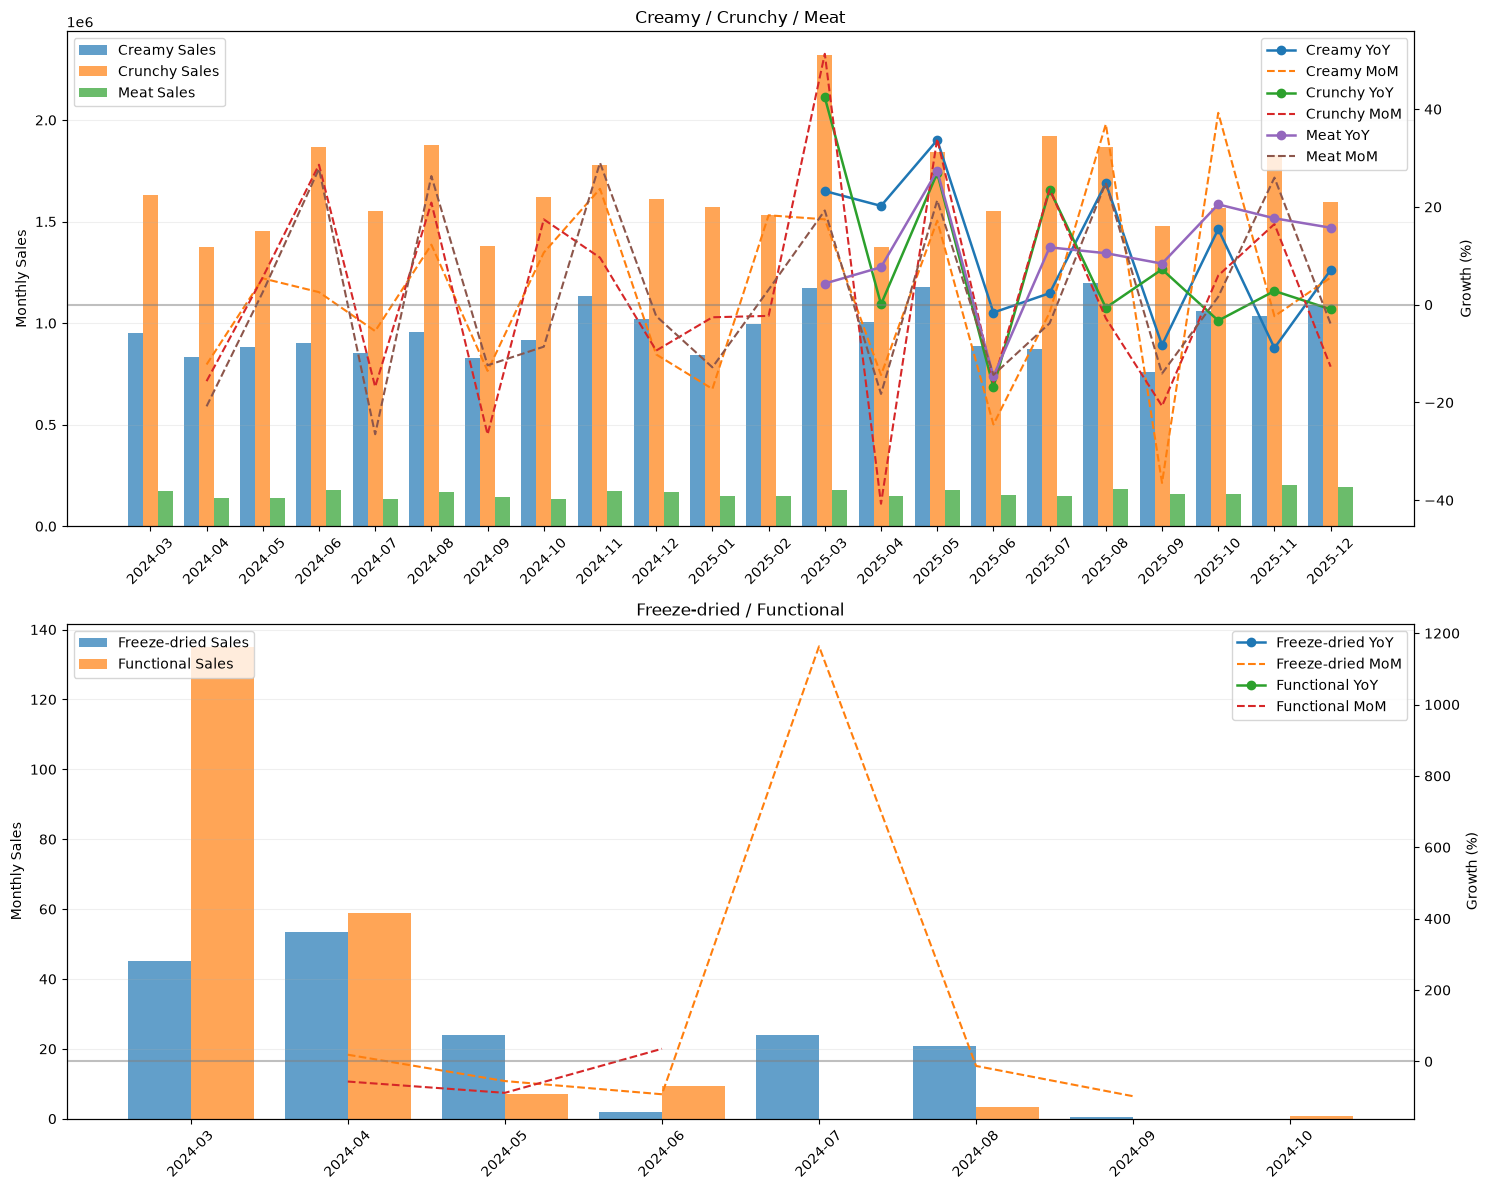

In [49]:
#4. Which segments are growing or declining, and why
def segment(name):
    name = str(name).upper()
    if any(x in name for x in ["CALMING", "DENTAL", "JOINT"]):
        return "Functional"
    elif any(x in name for x in ["CREAMY", "PUREE", "SPOONS"]):
        return "Creamy"
    elif "FREEZE DRIED" in name or "FREEZE-DRIED" in name:
        return "Freeze-dried"
    elif any(x in name for x in ["LOIN", "FILLET", "TENDER STICKS"]):
        return "Meat"
    elif any(x in name for x in ["CRUNCHERS", "NIBBLES", "PARTY MIX", "PLAY TUBES", "TEMPTATIONS"]):
        return "Crunchy"
    else:
        return "Other"
df["segment"] = df["product_name"].apply(segment)
display(df[["product_name","segment"]].drop_duplicates().sort_values("segment").head(3))

segment_monthly = df.groupby(["month", "segment"]).agg(
    sales = ("sales", "sum"), units = ("units", "sum")
).reset_index()
segment_monthly["asp"] = (segment_monthly["sales"]/segment_monthly["units"])
segment_monthly = segment_monthly.sort_values(["segment", "month"])
for metric in ["sales", "units", "asp"]:
    segment_monthly[f"{metric}_mom"] = (segment_monthly.groupby("segment")[metric].pct_change(fill_method=None) * 100)
    segment_monthly[f"{metric}_yoy"] = (segment_monthly.groupby("segment")[metric].pct_change(12, fill_method=None) * 100)
display(segment_monthly.round(2))



fig, axes = plt.subplots(2, 1, figsize=(15, 12))
groups = [["Creamy", "Crunchy", "Meat"], ["Freeze-dried", "Functional"]]
for ax1, segments in zip(axes, groups):
    data = segment_monthly[
        segment_monthly["segment"].isin(segments)
    ]
    sales = data.pivot(index="month", columns="segment", values="sales")
    x = np.arange(len(sales))
    width = 0.8 / len(segments)
    for i, seg in enumerate(segments):
        ax1.bar(
            x + (i - (len(segments)-1)/2) * width,
            sales[seg],
            width=width,
            alpha=0.7,
            label=f"{seg} Sales"
        )
    ax2 = ax1.twinx()
    for seg in segments:
        seg_data = data[data["segment"] == seg].set_index("month")
        seg_data = seg_data.reindex(sales.index)
        ax2.plot(
            x, seg_data["sales_yoy"],
            marker="o",
            linewidth=1.8,
            label=f"{seg} YoY"
        )
        ax2.plot(
            x, seg_data["sales_mom"],
            linestyle="--",
            linewidth=1.5,
            label=f"{seg} MoM"
        )
    ax1.set_xticks(x)
    ax1.set_xticklabels(sales.index.astype(str), rotation=45)
    ax1.set_ylabel("Monthly Sales")
    ax2.set_ylabel("Growth (%)")
    ax2.axhline(0, color="gray", alpha=0.5)
    ax1.set_title(" / ".join(segments))
    ax1.legend(loc="upper left")
    ax2.legend(loc="upper right")
    ax1.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()






Part3. Channel & Segment Dynamics

In [51]:
#1. Channel share and growth

for cha in ["instore", "online"]:
    monthly_pivot[f"{cha}_mom"] = (
        monthly_pivot[cha].pct_change(fill_method=None) * 100
    )
    monthly_pivot[f"{cha}_yoy"] = (
        monthly_pivot[cha].pct_change(12, fill_method=None) * 100
    )
display(
    monthly_pivot[
        ["instore_mom", "online_mom", "instore_yoy", "online_yoy", "online_share", "online_share_change"]
    ].round(2)
)

channel,instore_mom,online_mom,instore_yoy,online_yoy,online_share,online_share_change
month,,,,,,
2024-03,NaN,NaN,NaN,NaN,6.60,NaN
2024-04,-14.82,-14.32,NaN,NaN,6.64,0.04
2024-05,4.81,13.03,NaN,NaN,7.12,0.48
2024-06,19.27,19.89,NaN,NaN,7.15,0.03
2024-07,-14.11,-11.11,NaN,NaN,7.39,0.24
2024-08,18.00,21.74,NaN,NaN,7.60,0.21
2024-09,-21.25,-25.76,NaN,NaN,7.20,-0.40
2024-10,13.39,14.20,NaN,NaN,7.25,0.05
2024-11,14.69,24.98,NaN,NaN,7.84,0.59


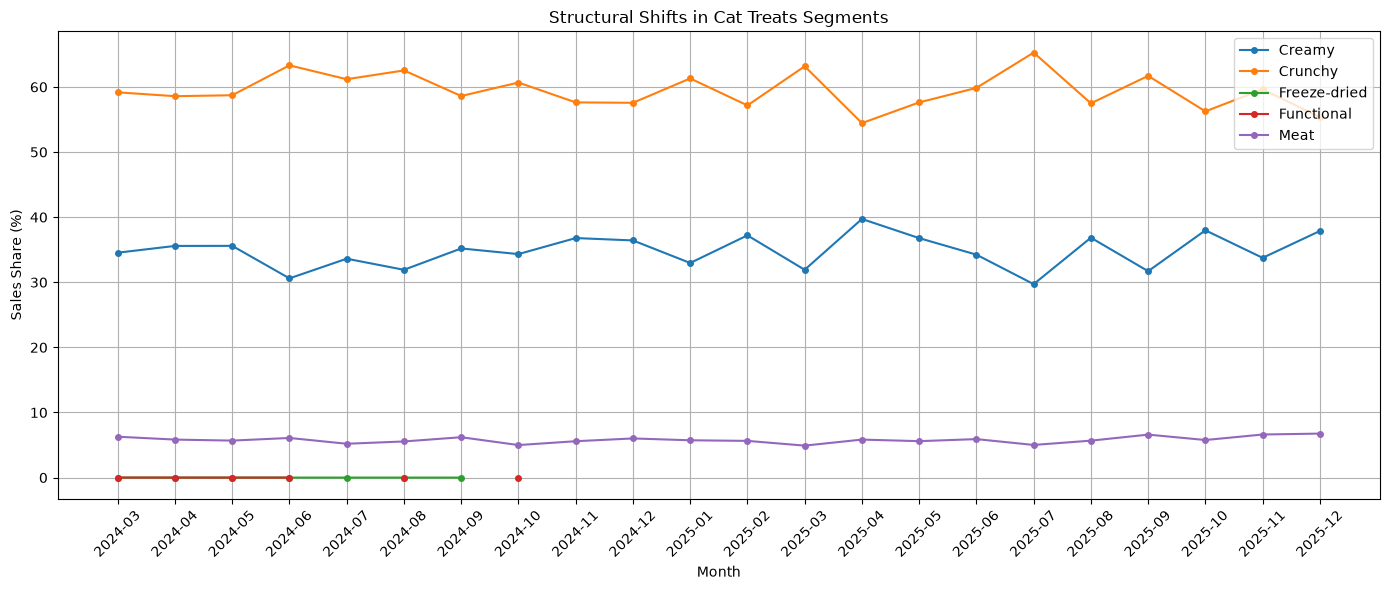

,2024_share,2025_share,change_pp
segment,,,
Creamy,34.405410,34.986645,0.581235
Crunchy,59.852080,59.184866,-0.667215
Freeze-dried,0.000629,0.000000,-0.000629
Functional,0.000795,0.000000,-0.000795
Meat,5.741086,5.828490,0.087404


Price threshold: 4.55
Higher-priced SKUs: 12


,sales_2024,sales_2025
tier,,
Higher-priced,50.34,52.31
Other,49.66,47.69


,sales_2024,sales_2025,growth_pct
tier,,,
Higher-priced,13581626.25,15141304.74,11.48
Other,13395972.19,13804655.64,3.05


In [ ]:
#2. Structural shifts
#Format Shift
segment_share = segment_monthly.pivot(
    index = "month",
    columns = "segment",
    values = "sales"
)
segment_share = (segment_share.div(segment_share.sum(axis=1), axis=0) * 100)
plt.figure(figsize=(14, 6))

for seg in segment_share.columns:
    plt.plot(
        range(len(segment_share)),
        segment_share[seg],
        marker="o",
        markersize=4,
        label=seg
    )
plt.title("Structural Shifts in Cat Treats Segments")
plt.xlabel("Month")
plt.ylabel("Sales Share (%)")
plt.xticks(
    range(len(segment_share)),
    segment_share.index.astype(str),
    rotation=45
)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

segment_yearly = df[df["month"].dt.month >= 3].groupby([df["date"].dt.year, "segment"])["sales"].sum().unstack(fill_value=0)
segment_yearly = segment_yearly.loc[[2024, 2025]]
segment_yearly_share = (segment_yearly.div(segment_yearly.sum(axis=1), axis=0)*100)
segment_change = pd.DataFrame({
    "2024_share": segment_yearly_share.loc[2024],
    "2025_share": segment_yearly_share.loc[2025]
})
segment_change["change_pp"] = (segment_change["2025_share"] - segment_change["2024_share"])
display(segment_change.round(6))

#Premiumization SKU，定义为价格前25%
base = df[df["date"].dt.year == 2024]
sku_price = base.groupby("product_id")[["sales", "units"]].sum()
sku_price = sku_price[sku_price["units"]>0]
sku_price["asp"] = sku_price["sales"] /sku_price["units"]
th = sku_price["asp"].quantile(0.75)
premium_ids = sku_price.index[sku_price["asp"]>=th]

print("Price threshold:", round(th, 2))
print("Higher-priced SKUs:", len(premium_ids))

premium = product_performance[product_performance.index.isin(sku_price.index)].copy()
premium["tier"] = np.where(premium.index.isin(premium_ids), "Higher-priced", "Other")
premium_sales = premium.groupby("tier")[["sales_2024", "sales_2025"]].sum()
premium_share = premium_sales.div(premium_sales.sum(axis=0), axis=1) * 100
premium_sales["growth_pct"]=(premium_sales["sales_2025"]/premium_sales["sales_2024"]-1)*100
display(premium_share.round(2))
display(premium_sales.round(2))
